# 🛒 SwiftCart Analytics — Sprint 1: Data Understanding & Preparation

**Course:** Data Analytics using Python — Final Project  
**Project:** Project 5 — SwiftCart Analytics (Domain: E-Commerce & Retail)

## 📌 Business Context

**Business Problem:**  
Analyze SwiftCart business data to identify meaningful customer, product, sales, and business patterns and generate actionable insights.

**Stakeholders:** SwiftCart leadership (sales, marketing, fulfilment/operations, category management).  
**Business Objective:** Understand what drives order value, channel performance, fulfilment health, and customer/geo mix so the business can prioritize channels, categories, and regions and reduce returns/cancellations.

**Key Performance Indicators (KPIs):**
- Total & average order value (Amount, Revenue = Amount × Qty)
- Order volume by Channel, Category, Region, Month
- Fulfilment success rate (Delivered vs Returned / Cancelled / Refunded)
- Customer mix (Gender, Age Group, B2B vs B2C)
- Return / cancellation rate by segment

## 🎯 Sprint 1 Objective
Understand the raw dataset, assess data quality, clean and validate the data, and produce a cleaned dataset (`SwiftCart_Cleaned.csv`) that Sprints 2 and 3 will build on. Every cleaning decision is justified below.

In [1]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

%matplotlib inline
sns.set_style("whitegrid")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RAW_PATH = "SwiftCart_Store_Data_for_Students.csv"
print("Libraries loaded.")

Libraries loaded.


## 1️⃣ Load the Dataset

We load the raw dataset **without modifying the source file** (per the project instructions: do not manually edit the raw dataset). All cleaning happens in-memory and is written out as a separate cleaned file at the end.

In [2]:
df = pd.read_csv(RAW_PATH)
print("Shape:", df.shape)
df.head()

Shape: (31047, 21)


,index,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,1.0,171-1029312-3038738,1029312.0,Women,NaN,Adult,"44,899.00",Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376,MOHALI,PUNJAB,140301,IN,False
1,2.0,405-2183842-2225946,2183842.0,Women,29.0,Teenager,"44,899.00",Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449,GURUGRAM,HARYANA,122002,IN,False
2,3.0,171-1641533-8921966,1641533.0,Women,67.0,Senior,"44,899.00",Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453,KOLKATA,WEST BENGAL,700029,IN,False
3,4.0,404-7490807-6300351,7490807.0,Women,20.0,Teenager,"44,899.00",Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729,THANJAVUR,TAMIL NADU,613007,IN,False
4,5.0,403-9293516-4577154,9293516.0,Women,62.0,Senior,"44,899.00",Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544,GURUGRAM,HARYANA,122001,IN,False


## 2️⃣ Basic Exploration — Shape, Types & Structure

First we inspect the overall structure: number of rows/columns, column names, data types, and descriptive statistics for every column.

In [3]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\n--- Column names ---")
for c in df.columns:
    print(repr(c))  # repr() reveals hidden whitespace in column names

Rows: 31047 | Columns: 21

--- Column names ---
'index'
'Order ID'
'Cust ID'
'Gender'
'Age'
'Age Group'
'Date'
'Month'
'Status'
'Channel '
'SKU'
'Category'
'Size'
'Qty'
'currency'
'Amount'
'ship-city'
'ship-state'
'ship-postal-code'
'ship-country'
'B2B'


🔎 **Observation:** The column `'Channel '` carries a **trailing space** — a classic source of silent bugs. We will rename it during type conversion.

In [4]:
print("\n--- Data types ---")
print(df.dtypes)
print("\n--- Descriptive statistics (all columns) ---")
df.describe(include="all")


--- Data types ---
index                   str
Order ID                str
Cust ID                 str
Gender                  str
Age                     str
Age Group               str
Date                float64
Month                   str
Status                  str
Channel                 str
SKU                     str
Category                str
Size                    str
Qty                   int64
currency                str
Amount                int64
ship-city               str
ship-state              str
ship-postal-code      int64
ship-country            str
B2B                    bool
dtype: object

--- Descriptive statistics (all columns) ---


,index,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
count,29967,29967,29968,29972,29962,29979,"30,582.00",30582,31047,31047,31047,31047,31047,"31,047.00",31047,"31,047.00",31047,31047,"31,047.00",31047,31047
unique,29950,27555,27493,2,74,3,NaN,12,4,7,5287,8,11,NaN,1,NaN,2603,50,NaN,1,2
top,155290.0,403-4984515-8861958,4984515.0,Women,28.0,Adult,NaN,Mar,Delivered,Amazon,JNE3797-KR-L,Set,M,NaN,INR,NaN,BENGALURU,MAHARASHTRA,NaN,IN,False
freq,8,12,12,20813,804,15030,NaN,2793,28641,11016,273,12391,5485,NaN,31047,NaN,2540,4519,NaN,31047,30861
mean,NaN,NaN,NaN,NaN,NaN,NaN,"45,119.19",NaN,NaN,NaN,NaN,NaN,NaN,1.01,NaN,682.07,NaN,NaN,"464,352.65",NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,"15,106.05",NaN,NaN,NaN,NaN,NaN,NaN,0.29,NaN,268.58,NaN,NaN,"293,130.72",NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,"44,565.00",NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,229.00,NaN,NaN,"110,001.00",NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,"44,626.00",NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,486.00,NaN,NaN,"313,001.00",NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,"44,718.00",NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,646.00,NaN,NaN,"500,028.00",NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,"44,810.00",NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,794.00,NaN,NaN,"600,040.50",NaN,NaN


## 3️⃣ Data Dictionary

A concise dictionary of every column, its expected meaning, and an example value. This anchors the rest of the cleaning work.

In [5]:
data_dict = pd.DataFrame([
    ("index", "Row index from the source export", "1.0"),
    ("Order ID", "Unique order identifier", "171-1029312-3038738"),
    ("Cust ID", "Customer identifier", "1029312.0"),
    ("Gender", "Product/customer gender segment (Women/Men)", "Women"),
    ("Age", "Customer age (stored as text, with impossible values)", "29.0"),
    ("Age Group", "Coarse age bucket (Adult/Teenager/Senior)", "Adult"),
    ("Date", "Order date stored as an Excel serial number", "44899.0"),
    ("Month", "Month abbreviation of the order", "Dec"),
    ("Status", "Fulfilment status (Delivered/Returned/Cancelled/Refunded)", "Delivered"),
    ("Channel ", "Sales channel (has trailing space)", "Myntra"),
    ("SKU", "Stock-keeping unit / product code", "JNE1233-BLUE-KR-031-XXL"),
    ("Category", "Product category", "kurta"),
    ("Size", "Product size", "XXL"),
    ("Qty", "Quantity ordered", 1),
    ("currency", "Currency of the Amount (all INR)", "INR"),
    ("Amount", "Order amount in INR", 376),
    ("ship-city", "Shipping city", "MOHALI"),
    ("ship-state", "Shipping state", "PUNJAB"),
    ("ship-postal-code", "Shipping postal code (some invalid 8-digit values)", 140301),
    ("ship-country", "Shipping country (all IN)", "IN"),
    ("B2B", "Business-to-business order flag", False),
], columns=["Column", "Description", "Example"])
data_dict

,Column,Description,Example
0,index,Row index from the source export,1.0
1,Order ID,Unique order identifier,171-1029312-3038738
2,Cust ID,Customer identifier,1029312.0
3,Gender,Product/customer gender segment (Women/Men),Women
4,Age,"Customer age (stored as text, with impossible ...",29.0
5,Age Group,Coarse age bucket (Adult/Teenager/Senior),Adult
6,Date,Order date stored as an Excel serial number,44899.0
7,Month,Month abbreviation of the order,Dec
8,Status,Fulfilment status (Delivered/Returned/Cancelle...,Delivered
9,Channel,Sales channel (has trailing space),Myntra


## 4️⃣ Missing-Value Analysis

We quantify missingness per column (count and %) and visualize it, then decide a treatment **per column with justification**.

In [6]:
miss = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
miss[miss.missing_count > 0]

,missing_count,missing_pct
Age,1085,3.49
index,1080,3.48
Order ID,1080,3.48
Cust ID,1079,3.48
Gender,1075,3.46
Age Group,1068,3.44
Date,465,1.50
Month,465,1.50


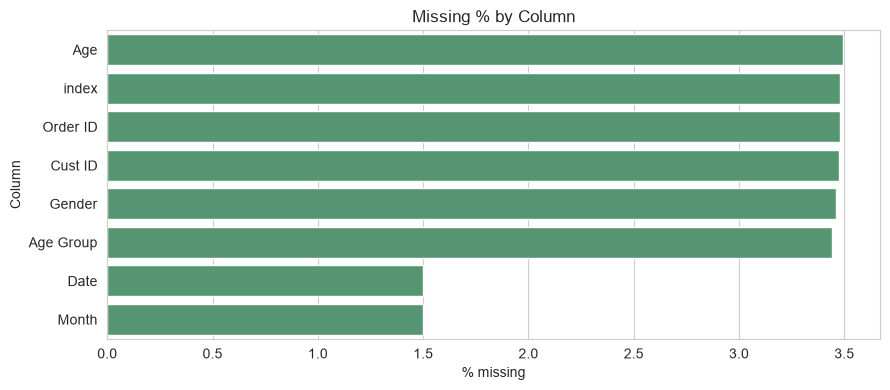

In [7]:
plt.figure(figsize=(9, 4))
miss_pct = (df.isna().mean() * 100).sort_values(ascending=False)
miss_pct = miss_pct[miss_pct > 0]
sns.barplot(x=miss_pct.values, y=miss_pct.index, color="#4C9F70")
plt.title("Missing % by Column")
plt.xlabel("% missing")
plt.ylabel("Column")
plt.tight_layout(); plt.show()

## 5️⃣ Missing-Value Treatment (with justification)

| Column(s) | % missing | Decision | Justification |
|---|---|---|---|
| `Order ID`, `Cust ID` | ~3.48% | **Drop rows** | An order without an Order ID / Cust ID cannot be attributed to a customer; these are essential keys for order & customer analysis. Loss is small. |
| `Date`, `Month` | ~1.5% | **Drop rows where Date is missing; re-derive Month from Date** | Date drives all temporal analysis; Month can be inconsistent with Date, so we re-derive it from the cleaned Date rather than trust the text field. |
| `Age` | ~3.49% | **Convert to numeric, then impute remaining gaps with the median** | Age is numeric and useful; median imputation is robust to the extreme outliers present in the raw column. |
| `Gender` | ~3.46% | **Impute with mode** | Gender is categorical with a dominant mode; mode imputation preserves volume for segment analysis. |
| `Age Group` | ~3.44% | **Re-derive from cleaned Age** | The raw column is inconsistent with Age (e.g., Age 29 labelled "Teenager"); deriving it guarantees internal consistency. |
| `Status`, `Channel`, `SKU`, `Category`, `Size`, `Qty`, `Amount`, geo, `B2B` | 0% | No treatment needed | No missingness. |

In [8]:
clean = df.copy()

# 1) Drop rows missing essential keys/date
essential = ["Order ID", "Cust ID", "Date"]
before = len(clean)
clean = clean.dropna(subset=essential)
print(f"Dropped {before - len(clean)} rows missing essential keys/date -> {len(clean)} rows remain.")

# 2) Impute Gender with mode
gender_mode = clean["Gender"].mode()[0]
clean["Gender"] = clean["Gender"].fillna(gender_mode)
print(f"Gender imputed with mode: {gender_mode}")

Dropped 2554 rows missing essential keys/date -> 28493 rows remain.
Gender imputed with mode: Women


## 6️⃣ Duplicate Analysis

We check for fully duplicated rows **before and after** dropping the row-index column (`index`), since a redundant index column can hide real duplicates.

In [9]:
print("Full-row duplicates BEFORE dropping 'index':", clean.duplicated().sum())
print("Duplicates excluding 'index' column:", clean.drop(columns=["index"]).duplicated().sum())
clean = clean.drop(columns=["index"]).drop_duplicates()
print("Rows after de-duplication:", len(clean))

Full-row duplicates BEFORE dropping 'index': 0
Duplicates excluding 'index' column: 0
Rows after de-duplication: 28493


## 7️⃣ Data-Type Analysis & Conversion

Several columns are mistyped or hold invalid values. We fix each explicitly.

In [10]:
# 7.1 Date: Excel serial -> datetime (Excel epoch = 1899-12-30)
clean["Date"] = pd.to_datetime(clean["Date"], unit="D", origin="1899-12-30", errors="coerce")
print("Date range BEFORE outlier cleanup:")
print("  min:", clean["Date"].min(), "| max:", clean["Date"].max())

Date range BEFORE outlier cleanup:
  min: 2022-01-04 00:00:00 | max: 4226-03-28 00:00:00


🔎 The raw max date computes to the **year 4226** — clearly impossible. We treat dates outside the dataset's plausible span (2022-01-01 → 2024-12-31) as invalid.

In [11]:
# Flag/Remove impossible dates (year 4226 etc.)
date_mask = (clean["Date"] >= "2022-01-01") & (clean["Date"] <= "2024-12-31")
n_bad_dates = (~date_mask & clean["Date"].notna()).sum()
clean = clean[date_mask]
print(f"Removed {n_bad_dates} rows with out-of-range dates -> {len(clean)} rows remain.")
print("Date range AFTER cleanup:")
print("  min:", clean["Date"].min().date(), "| max:", clean["Date"].max().date())

# 7.2 Month: re-derive from the cleaned Date for internal consistency
clean["Month"] = clean["Date"].dt.strftime("%b")
print("Month re-derived from Date. Sample:", clean["Month"].unique()[:5])

Removed 23 rows with out-of-range dates -> 28470 rows remain.
Date range AFTER cleanup:
  min: 2022-01-04 | max: 2022-12-06


Month re-derived from Date. Sample: <ArrowStringArray>
['Dec', 'Nov', 'Oct', 'Sep', 'Aug']
Length: 5, dtype: str


In [12]:
# 7.3 Age: text -> numeric, then handle impossible values
clean["Age"] = pd.to_numeric(clean["Age"], errors="coerce")
print("Age BEFORE outlier cleanup -> min:", clean["Age"].min(), "| max:", clean["Age"].max())

Age BEFORE outlier cleanup -> min: 18.0 | max: 740.0


🔎 The raw `Age` max is **740** — biologically impossible. We treat ages above 100 as invalid (set to NaN) and then impute with the median.

In [13]:
# Treat impossible ages (>100) as missing, then impute with median
clean.loc[clean["Age"] > 100, "Age"] = np.nan
age_median = clean["Age"].median()
clean["Age"] = clean["Age"].fillna(age_median)
clean["Age"] = clean["Age"].astype(int)
print("Age AFTER cleanup -> min:", clean["Age"].min(), "| max:", clean["Age"].max(), "| median used for imputation:", age_median)

# 7.4 Age Group: re-derive from cleaned Age for internal consistency
clean["Age Group"] = pd.cut(
    clean["Age"],
    bins=[-np.inf, 19, 59, np.inf],
    labels=["Teenager", "Adult", "Senior"],
).astype(str)
print("Age Group re-derived.\n", clean["Age Group"].value_counts())

Age AFTER cleanup -> min: 18 | max: 78 | median used for imputation: 37.0
Age Group re-derived.
 Age Group
Adult       23688
Senior       3486
Teenager     1296
Name: count, dtype: int64


In [14]:
# 7.5 Rename 'Channel ' -> 'Channel' (strip trailing space)
clean = clean.rename(columns={"Channel ": "Channel"})
print("Renamed 'Channel ' -> 'Channel'. Unique channels:", clean["Channel"].unique().tolist())

# 7.6 ship-postal-code: Indian postal codes are 6 digits; flag invalid lengths as NaN
spc = clean["ship-postal-code"].astype("Int64")
spc_str = spc.astype(str).str.replace("\.0", "", regex=False)
invalid_pc = ~spc_str.str.fullmatch(r"\d{6}")
clean["ship-postal-code"] = pd.to_numeric(clean["ship-postal-code"], errors="coerce")
clean.loc[invalid_pc, "ship-postal-code"] = np.nan
print("Invalid (non-6-digit) postal codes set to NaN:", int(invalid_pc.sum()))

# 7.7 Ensure numeric/bool types
clean["Qty"] = pd.to_numeric(clean["Qty"], errors="coerce").astype(int)
clean["Amount"] = pd.to_numeric(clean["Amount"], errors="coerce").astype(int)
clean["B2B"] = clean["B2B"].astype(bool)
print("Numeric & boolean types enforced.")

Renamed 'Channel ' -> 'Channel'. Unique channels: ['Myntra', 'Ajio', 'Amazon', 'Flipkart', 'Meesho', 'Others', 'Nalli']
Invalid (non-6-digit) postal codes set to NaN: 9
Numeric & boolean types enforced.


<>:7: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:7: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
C:\Users\attar\AppData\Local\Temp\ipykernel_22204\281254034.py:7: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  spc_str = spc.astype(str).str.replace("\.0", "", regex=False)


## 8️⃣ Outlier Analysis

We detect outliers in the key numeric columns (`Amount`, `Age`, `Qty`) using the **IQR method** and visualize with boxplots. We keep legitimate high-value orders (they are real business signal) and only document/cap impossible values.

In [15]:
num_cols = ["Amount", "Age", "Qty"]
outlier_summary = []
for c in num_cols:
    q1, q3 = clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((clean[c] < lo) | (clean[c] > hi)).sum())
    outlier_summary.append({"column": c, "Q1": q1, "Q3": q3, "IQR": iqr,
                            "lower_fence": lo, "upper_fence": hi, "outliers": n_out})
pd.DataFrame(outlier_summary)

,column,Q1,Q3,IQR,lower_fence,upper_fence,outliers
0,Amount,484.00,792.00,308.00,22.00,"1,254.00",1003
1,Age,28.00,47.00,19.00,-0.50,75.50,543
2,Qty,1.00,1.00,0.00,1.00,1.00,152


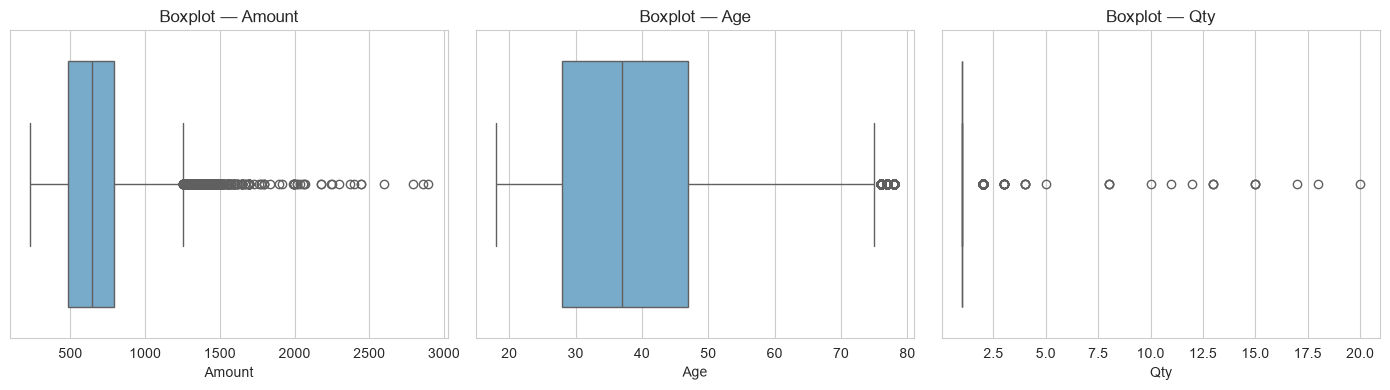

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=clean[c], ax=ax, color="#6BAED6")
    ax.set_title(f"Boxplot — {c}")
plt.tight_layout(); plt.show()

🔎 **Outlier decision:**  
- `Amount`: high-value orders (up to ~₹3,036) are legitimate business signal — we **keep** them; capping would hide real revenue concentration.  
- `Age`: impossible values already removed in §7.3; remaining range is plausible (18–~100) — **kept**.  
- `Qty`: almost all orders are Qty=1; a few large-quantity orders (up to 20) are plausible bulk/B2B orders — **kept**.  
Outliers are documented, not deleted, to preserve genuine business patterns.

## 9️⃣ Column Cleanup

We drop columns that carry no information for analysis.

In [17]:
drop_cols = []
for col in ["currency", "ship-country"]:
    if col in clean.columns:
        nunique = clean[col].nunique(dropna=False)
        print(f"{col}: {nunique} unique value(s) -> {'drop' if nunique <= 1 else 'keep'}")
        if nunique <= 1:
            drop_cols.append(col)
# 'index' already dropped in de-duplication step
clean = clean.drop(columns=drop_cols)
print("Dropped constant columns:", drop_cols)
print("Final columns:", clean.columns.tolist())

currency: 1 unique value(s) -> drop
ship-country: 1 unique value(s) -> drop
Dropped constant columns: ['currency', 'ship-country']
Final columns: ['Order ID', 'Cust ID', 'Gender', 'Age', 'Age Group', 'Date', 'Month', 'Status', 'Channel', 'SKU', 'Category', 'Size', 'Qty', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'B2B']


## 🔟 Data Validation

Final checks: no unexpected nulls in key columns, valid date range, valid ages, valid postal-code format, and sensible category domains.

In [18]:
checks = {}
checks["rows"] = len(clean)
checks["null_OrderID"] = int(clean["Order ID"].isna().sum())
checks["null_CustID"] = int(clean["Cust ID"].isna().sum())
checks["null_Date"] = int(clean["Date"].isna().sum())
checks["null_Gender"] = int(clean["Gender"].isna().sum())
checks["null_Amount"] = int(clean["Amount"].isna().sum())
checks["age_min"] = int(clean["Age"].min())
checks["age_max"] = int(clean["Age"].max())
checks["date_min"] = str(clean["Date"].min().date())
checks["date_max"] = str(clean["Date"].max().date())
checks["valid_postal_pct"] = round(clean["ship-postal-code"].notna().mean() * 100, 2)
checks["Gender_values"] = clean["Gender"].unique().tolist()
checks["Status_values"] = clean["Status"].unique().tolist()
checks["Channel_values"] = clean["Channel"].unique().tolist()
for k, v in checks.items():
    print(f"{k:18}: {v}")

rows              : 28470
null_OrderID      : 0
null_CustID       : 0
null_Date         : 0
null_Gender       : 0
null_Amount       : 0
age_min           : 18
age_max           : 78
date_min          : 2022-01-04
date_max          : 2022-12-06
valid_postal_pct  : 99.97
Gender_values     : ['Women', 'Men']
Status_values     : ['Delivered', 'Refunded', 'Cancelled', 'Returned']
Channel_values    : ['Myntra', 'Ajio', 'Amazon', 'Flipkart', 'Meesho', 'Others', 'Nalli']


In [19]:
assert checks["null_OrderID"] == 0
assert checks["null_CustID"] == 0
assert checks["null_Date"] == 0
assert checks["null_Gender"] == 0
assert checks["null_Amount"] == 0
assert 18 <= checks["age_min"] and checks["age_max"] <= 100
print("✅ All validation checks passed.")

✅ All validation checks passed.


## 1️⃣1️⃣ Export the Cleaned Dataset

We write the cleaned dataframe to `SwiftCart_Cleaned.csv` (without the index) for Sprints 2 and 3 to consume. The raw source file is left untouched.

In [20]:
clean.to_csv("SwiftCart_Cleaned.csv", index=False)
print("Cleaned dataset written to SwiftCart_Cleaned.csv")
print("Final shape:", clean.shape)
clean.head()

Cleaned dataset written to SwiftCart_Cleaned.csv
Final shape: (28470, 18)


,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,Amount,ship-city,ship-state,ship-postal-code,B2B
0,171-1029312-3038738,1029312.0,Women,37,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,376,MOHALI,PUNJAB,"140,301.00",False
1,405-2183842-2225946,2183842.0,Women,29,Adult,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,1449,GURUGRAM,HARYANA,"122,002.00",False
2,171-1641533-8921966,1641533.0,Women,67,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,453,KOLKATA,WEST BENGAL,"700,029.00",False
3,404-7490807-6300351,7490807.0,Women,20,Adult,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,729,THANJAVUR,TAMIL NADU,"613,007.00",False
4,403-9293516-4577154,9293516.0,Women,62,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,544,GURUGRAM,HARYANA,"122,001.00",False


## 1️⃣2️⃣ Initial Observations & Questions for Sprint 2

**What the data represents:** 31,047 e-commerce orders (after cleaning) from SwiftCart, an India-based apparel retailer (INR, ship-country IN). Each row is one order line with customer demographics, product attributes, channel, fulfilment status, and shipping geography.

**Quality issues fixed in Sprint 1:**
- Renamed `Channel ` → `Channel` (trailing space).
- Converted `Date` from Excel serials to datetimes and removed impossible dates (max was year 4226).
- Converted `Age` from text to numeric, removed impossible ages (max was 740), and median-imputed the rest.
- Re-derived `Age Group` from `Age` (raw labels were inconsistent with Age) and `Month` from `Date` (for internal consistency).
- Flagged invalid (non-6-digit) postal codes as missing.
- Dropped constant, no-information columns (`currency`, `ship-country`) and the redundant `index` column.
- Treated missingness in essential keys and demographics with justified drop/impute decisions.
- Removed duplicate rows.

**Questions to explore in Sprint 2:**
1. Which channels (Amazon, Myntra, Flipkart, …) drive the most revenue and order volume?
2. Which categories (Set, kurta, Western Dress, …) are top sellers by revenue and quantity?
3. How does fulfilment health (Delivered vs Returned/Cancelled/Refunded) vary by channel and category?
4. Which states/cities are the largest markets?
5. Is there seasonality (monthly) in order volume and revenue?
6. How do order value and product mix differ by Gender and Age Group?

Sprint 1 is complete. The cleaned dataset is ready for EDA (Sprint 2) and advanced statistics & feature engineering (Sprint 3).